# Long Valley time-lapse gravity: from archive to paired observations

## Objectives

1. Audit a real multi-epoch gravity table without filling missing visits.
2. Compute station-matched temporal differences and propagate supplied 1-SD errors under an explicit independence assumption.
3. Inspect the spatial network and a station history without inventing a raster.
4. Explain why raw epoch differences do not identify a magma or density source.

## Setup

Use the repository's pinned notebook environment. Obtain and verify the compact source files first. This lesson never downloads data, installs packages, or starts an inversion.
Reference environment pin (shown for reproduction; the notebook does not install packages):
```text
pip install numpy==2.2.6 pandas==2.2.3 matplotlib==3.10.8
```

In [1]:
# Execute the reviewed source-bound observation calculation.
from pathlib import Path
import json
import sys, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd().parents[2]
sys.path.insert(0, str(root / "data-pipeline"))
from long_valley_timelapse import parse_source, difference, build_artifact
source_path = root / "data/downloads/long-valley/GravitySurveys.txt"
metadata_path = root / "data/downloads/long-valley/gravitymetadata.htm"
source = parse_source(source_path)
EARLIER, LATER = "1982-06", "1999-07"
paired = pd.DataFrame(difference(source, EARLIER, LATER)["stations"])
print("Gravity table SHA-256:", hashlib.sha256(source_path.read_bytes()).hexdigest())
from importlib.metadata import version
print("Python scientific packages:", {name: version(name) for name in ("numpy", "pandas", "matplotlib")})


Gravity table SHA-256: d7cca18741ef85fa7ea6fe448dabfee40900de6ed45ba5ea3d13b9e9f9ec1424
Python scientific packages: {'numpy': '2.2.6', 'pandas': '2.2.3', 'matplotlib': '3.10.8'}


## Data

This lesson uses `GravitySurveys.txt` and its FGDC metadata from the USGS *Long Valley Caldera GIS Database*, DDS-81 (2003). The table reports 37 stations, occupations from 1980–1999, gravity and 1-SD errors in mGal, and source-reported UTM/NAD27 coordinates in metres. The network description says solid Earth tides and daily gravimeter drift were removed and repeat readings were least-squares averaged. The 1998/1999 occupations are credited to Stanford's Crustal Deformation Group; retain the full DDS-81 author list when citing the data.

The FGDC record says access and use constraints are none and requests acknowledgement. Run `python scripts/download_long_valley.py` from the repository root before this lesson; the downloader accepts only pinned USGS URLs and checks source identity. See [the source and processing record](../../../docs/research/long-valley-field-time-lapse.md).

### Occupation coverage

The table has missing visits. A missing visit is not a zero gravity reading. The next cell separates the station-epoch observation count from the number of common stations in a selected pair.

In [2]:
# Execute the reviewed source-bound observation calculation.
records = [{"station_id": s["station_id"], "easting_m": s["easting_m"], "northing_m": s["northing_m"], **m} for s in source["stations"] for m in s["measurements"]]
measurements = pd.DataFrame.from_records(records)
coverage = measurements.groupby("epoch").agg(stations=("station_id", "nunique"), mean_sigma_mgal=("sigma_mgal", "mean")).reindex(source["epochs"])
print("Stations:", len(source["stations"]), "· measurements:", len(measurements))
coverage

Stations: 37 · measurements: 212


,stations,mean_sigma_mgal
epoch,,
1980-06,16,0.002500
1982-06,37,0.004946
1982-09,24,0.005217
1983-07,33,0.004361
1984-07,23,0.007039
1985-07,10,0.004610
1998-07,32,0.008031
1999-07,37,0.006784


### Map the sampled stations

Each symbol is an actual station coordinate and colour encodes paired observed Δg. The map draws no contours, interpolates no values, and infers no active cells. The source format page reports UTM/NAD27 but omits a UTM zone; preserve source easting/northing rather than silently reprojecting.

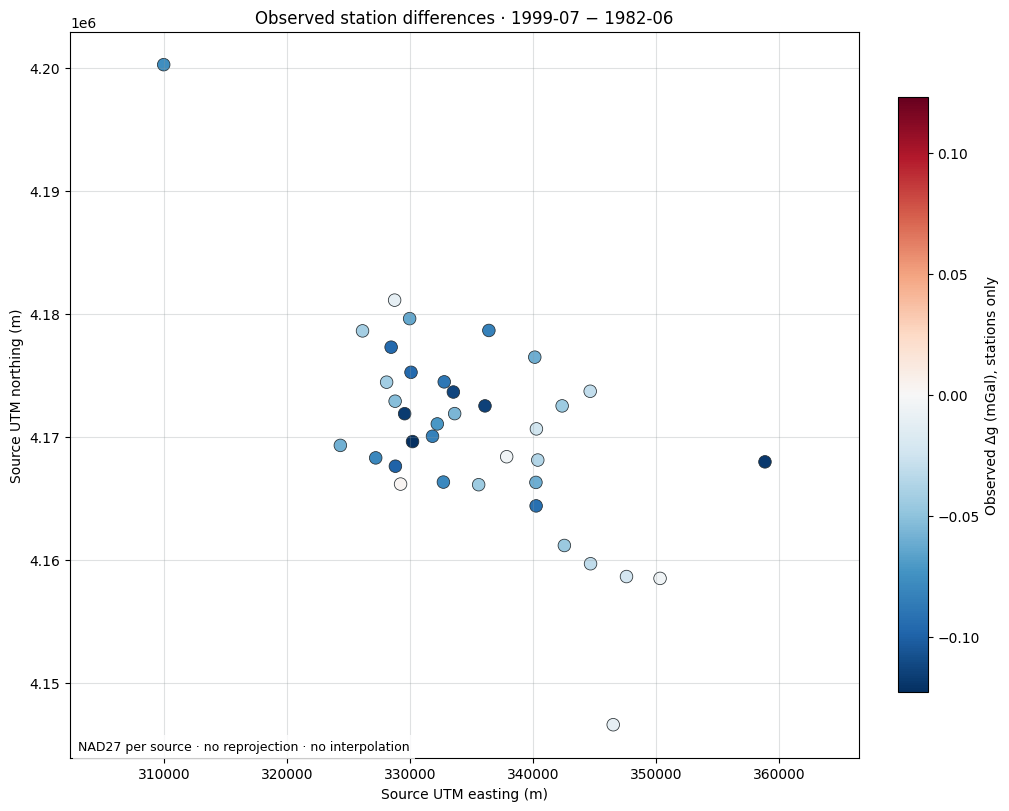

In [3]:
# Execute the reviewed source-bound observation calculation.
fig, ax = plt.subplots(figsize=(10,8), layout="constrained")
limit = float(np.abs(paired.delta_gravity_mgal).max())
sc = ax.scatter(paired.easting_m, paired.northing_m, c=paired.delta_gravity_mgal, cmap="RdBu_r", vmin=-limit, vmax=limit, s=82, edgecolors="#252d31", linewidths=.55)
ax.set_aspect("equal", adjustable="datalim")
ax.set(title=f"Observed station differences · {LATER} − {EARLIER}", xlabel="Source UTM easting (m)", ylabel="Source UTM northing (m)")
ax.grid(color="#8d9698", alpha=.28)
fig.colorbar(sc, ax=ax, shrink=.82, label="Observed Δg (mGal), stations only")
ax.text(.01,.01,"NAD27 per source · no reprojection · no interpolation",transform=ax.transAxes,fontsize=9,bbox={"facecolor":"white","alpha":.8,"edgecolor":"none"})
plt.show()

### Follow one station through time

This trace is relative to that station's first available occupation. Error bars use the independent-epoch propagation assumption. The absolute observations are near 979,000 mGal, so the offset makes small temporal changes visible while the table retains original values.

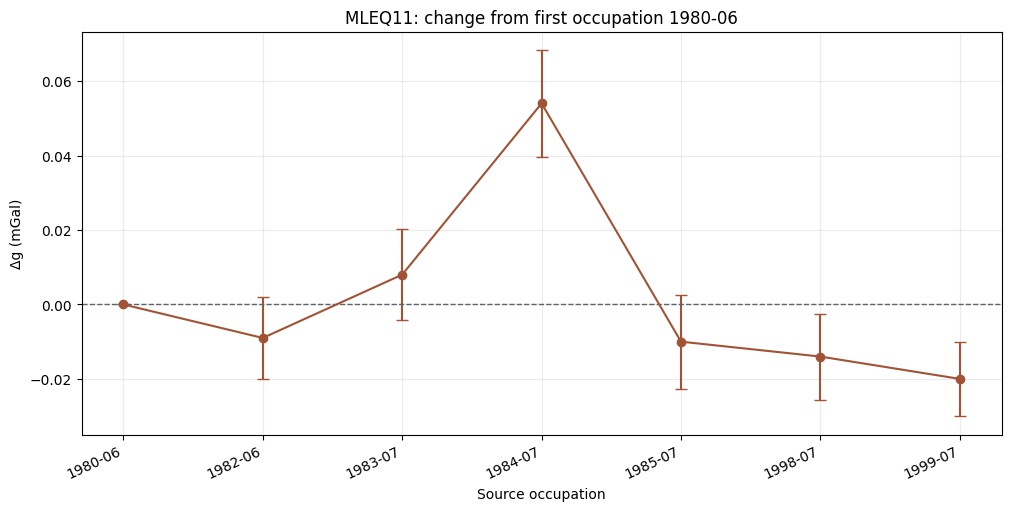

In [4]:
# Execute the reviewed source-bound observation calculation.
station_id = "MLEQ11"
station = next(s for s in source["stations"] if s["station_id"] == station_id)
history = pd.DataFrame(station["measurements"])
reference = history.iloc[0]
history["delta_mgal"] = history.gravity_mgal - reference.gravity_mgal
history["sigma_delta_independent_mgal"] = np.hypot(history.sigma_mgal, reference.sigma_mgal)
history.loc[history.index[0], "sigma_delta_independent_mgal"] = 0.0
fig, ax = plt.subplots(figsize=(10,5),layout="constrained")
x=np.arange(len(history))
ax.errorbar(x,history.delta_mgal,yerr=history.sigma_delta_independent_mgal,marker="o",capsize=4,color="#a25335")
ax.axhline(0,color="#59666b",linewidth=1,linestyle="--")
ax.set_xticks(x,history.epoch,rotation=25,ha="right")
ax.set(title=f"{station_id}: change from first occupation {reference.epoch}",xlabel="Source occupation",ylabel="Δg (mGal)")
ax.grid(alpha=.25)
plt.show()

### Covariance sensitivity

For correlation ρ, variance of a difference is σA² + σB² − 2ρσAσB. Because ρ is not supplied, inspect how propagated uncertainty changes across plausible correlations. The ρ=0 point is the declared default, not a selected or calibrated covariance.

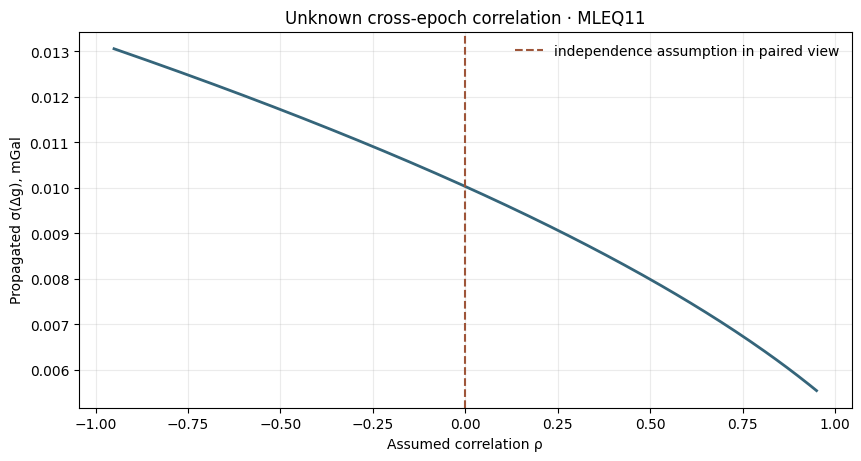

In [5]:
# Execute the reviewed source-bound observation calculation.
rho=np.linspace(-.95,.95,191)
a,b=history.iloc[0],history.iloc[-1]
sigma=np.sqrt(np.maximum(a.sigma_mgal**2+b.sigma_mgal**2-2*rho*a.sigma_mgal*b.sigma_mgal,0))
fig,ax=plt.subplots(figsize=(8.5,4.5),layout="constrained")
ax.plot(rho,sigma,color="#35657a",linewidth=2)
ax.axvline(0,color="#9e5539",linestyle="--",label="independence assumption in paired view")
ax.set(title=f"Unknown cross-epoch correlation · {station_id}",xlabel="Assumed correlation ρ",ylabel="Propagated σ(Δg), mGal")
ax.grid(alpha=.25); ax.legend(frameon=False); plt.show()

## Method

For station *i* and occupation *t*, the archived value is a processed field observation with reported standard deviation. For selected epochs A and B:

$$
\Delta g_i = g_{i,B}-g_{i,A}.
$$

If epoch errors are independent, the working uncertainty is

$$
\sigma_{\Delta,i}=\sqrt{\sigma_{i,A}^2+\sigma_{i,B}^2}.
$$

The archive gives no cross-epoch covariance. Independence is a view assumption, not a measured property. Only stations with both observations and both errors enter a pair.

For a fixed station, subtraction suppresses its unknown but stable absolute offset. It does not suppress epoch-specific instrument drift, a changed benchmark, shared reference-network error, subsurface hydrology, or vertical motion. A bookkeeping model is

$$
\\Delta g_{obs,i}=\\Delta g_{mass,i}+C_{deformation,i}+\\Delta g_{hydro,i}+b_{epoch}+\\epsilon_i.
$$

These terms are contributions to the measured change, not quantities separated by this notebook. The archive's reported standard deviations describe occupation precision; they do not include every systematic term. Published Long Valley studies combine gravity with deformation observations and hydrologic corrections before fitting a source. This table has no station elevations or water-table series, so calculating those corrections here would require invented inputs.

The pair routine joins on exact station identifier and keeps stations with both values and positive errors. Missing values remain missing. For a pair, the independent working variance follows

$$
\\operatorname{Var}(g_B-g_A)=\\sigma_A^2+\\sigma_B^2-2\\operatorname{Cov}(g_A,g_B),
$$

which becomes a root-sum-square only when covariance is set to zero. The source does not provide covariance. The sensitivity plot varies a correlation assumption over its admissible range while leaving observations unchanged; it does not estimate correlation from two standard deviations. Shared calibration error can correlate epochs, while changed instrumentation or processing can change that relationship. The error bar can shrink or grow with correlation, but the difference itself does not.

Coordinates remain source-reported UTM/NAD27 eastings and northings. The table omits the UTM zone, station elevations and datum transformation. The map is therefore a sampling map only: not a regular grid, complete survey footprint, or density image. A 37-station pair is sparse relative to the caldera's structural and hydrothermal complexity; interpolation would create spatial continuity the observations do not establish.

The 1JD1952 flag is bound to the source-table hash and exact observation tuple. The pipeline does not replace it using an older report because station identity and epoch alignment remain unverified. Exclusion is reproducible by default; explicit inclusion exposes the effect. This is a provenance decision, not automatic outlier rejection. A standardized difference is a quotient under assumed uncertainty, not a p-value or detection probability while covariance, selection and model errors remain uncharacterized.

The reported sigma is a source-provided one-standard-deviation value after the archive's stated repeat averaging; it is not a complete uncertainty budget for a temporal interpretation. Instrument scale-factor uncertainty, baseline stability, reference-station transfer, monument disturbance, and the covariance introduced by a joint least-squares network adjustment may be shared across visits. If the archive later supplies covariance, use it directly rather than estimating a correlation from marginal errors. If only bounds are known, report a sensitivity interval and keep the raw difference separate from any corrected residual.

Long Valley is a volcanic-hydrothermal system. A gravity decrease can arise from vertical uplift because the station moves farther from subsurface mass; water-table decline can also lower gravity by removing near-surface water mass. Intrusion may add mass, but the measured sign and amplitude combine these processes. The 1999 paper's corrected positive residual cannot be inferred from the current raw pair alone. It used a specific correction workflow and independent geodetic/hydrologic observations; different epoch selection also matters. This distinction is central to time-lapse geophysics: repeatability, correction provenance and a forward model are needed before a temporal residual is assigned to a reservoir or magma source.

The observed table is a historical monitoring archive rather than a uniform modern survey. Reoccupation intervals vary, some station/epoch cells are blank, and reported errors differ. A complete analysis would inspect instrument lineage and station stability, compare each epoch's occupied subset, use common reference stations, and examine possible spatially correlated adjustment error. The exercise deliberately does not interpolate a smooth field from sparse points: such a map would visually conceal nonuniform coverage, source-frame ambiguity and correction uncertainty.

A mass-source interpretation requires an explicit forward model with station geometry, density contrast, depth, and a stated parameterization. Many different source shapes can fit sparse gravity data within measurement error; a matching temporal curve does not prove a unique magma geometry. Before inversion, establish whether deformation and hydrologic corrections are available for each station and epoch, whether their uncertainty is independent or shared, and whether the retained stations resolve the proposed source. Compare predictions on held-out stations where feasible and report sensitivity to source depth, density, and reference model. Until those checks are performed, this case is valuable precisely because it stops at a defensible observation product rather than filling the missing physical terms with zeros.

Reference choice also affects what a plotted station history means. The history plot subtracts the first available occupation for that station, so its zero is local to that station and may correspond to a different calendar date for another station. It is not a network-adjusted common datum. A pairwise comparison instead fixes the same two epoch labels for all stations and reports only their common subset. Keep these two views distinct: a within-station trace is useful for detecting unusual chronology, while a common-epoch map supports spatial comparison only when station coverage and reference stability are stated. Neither view removes shared epoch bias.


### Compare epoch pairs and published context

The same station matching and uncertainty calculation applies to other occupations. Pair coverage changes because not every station was occupied at every epoch. Long-period changes may include deformation and hydrologic effects; these columns do not separate those causes.

A quantitative literature check shows why epoch matching and correction history matter. Battaglia, Roberts and Segall (1999) report Long Valley gravity decreases up to −107 ± 6 μGal over 1982–1998; after corrections for uplift and water-table fluctuations, they report a positive residual change up to +64 ± 15 μGal. Converting microgal to mGal divides by 1000. The sign reversal is physical separation of deformation and hydrologic contributions, not a display choice. This notebook's default pair is June 1982–July 1999, and its table lacks the elevations and water-level observations needed to reproduce the correction. Thus the published values are context, not a numeric validation target for this uncorrected pair. Jachens and Roberts (1985) likewise describe temporal changes complicated by water-table depth changes. The next step is to acquire source-matched correction observations and errors, then reproduce a documented reduction before fitting a physical source.


In [6]:
# Execute the reviewed source-bound observation calculation.
pairs=[("1982-06","1998-07"),("1982-06","1999-07"),("1982-09","1999-07"),("1985-07","1999-07")]
comparison=[]
for first,last in pairs:
 r=pd.DataFrame(difference(source,first,last)["stations"])
 comparison.append({"A":first,"B":last,"paired_stations":len(r),"median_delta_mgal":r.delta_gravity_mgal.median(),"range_min_mgal":r.delta_gravity_mgal.min(),"range_max_mgal":r.delta_gravity_mgal.max(),"median_independent_sigma_mgal":r.delta_sigma_independent_mgal.median()})
pd.DataFrame(comparison)

,A,B,paired_stations,median_delta_mgal,range_min_mgal,range_max_mgal,median_independent_sigma_mgal
0,1982-06,1998-07,32,-0.0595,-0.107,-0.002,0.008544
1,1982-06,1999-07,37,-0.0600,-0.123,0.002,0.007211
2,1982-09,1999-07,23,-0.0650,-0.229,0.065,0.008345
3,1985-07,1999-07,10,0.0085,-0.234,0.153,0.007162


The cited publication reports its raw and corrected signals in microgal. Convert units but keep its 1982–1998 interval distinct from this notebook’s 1982–1999 archive pair.

In [7]:
# Convert the cited publication values and their 1-SD errors from microgal to mGal.
published_raw_microgal, published_raw_sigma_microgal = -107.0, 6.0
published_residual_microgal, published_residual_sigma_microgal = 64.0, 15.0
published_raw_mgal, published_raw_sigma_mgal = published_raw_microgal / 1000.0, published_raw_sigma_microgal / 1000.0
published_residual_mgal, published_residual_sigma_mgal = published_residual_microgal / 1000.0, published_residual_sigma_microgal / 1000.0
print({"Battaglia_1999_raw_change_mgal": (published_raw_mgal, published_raw_sigma_mgal),
       "after_uplift_and_water_table_correction_mgal": (published_residual_mgal, published_residual_sigma_mgal),
       "same_epoch_pair_as_this_notebook": False})


{'Battaglia_1999_raw_change_mgal': (-0.107, 0.006), 'after_uplift_and_water_table_correction_mgal': (0.064, 0.015), 'same_epoch_pair_as_this_notebook': False}


## Results

The default pair is June 1982 to July 1999. Inspect all matched stations and sort by absolute change. A standardized difference is only a quotient under independent errors; it is not a detection probability, hypothesis test, or corrected residual.

In [8]:
# Execute the reviewed source-bound observation calculation.
EARLIER, LATER = "1982-06", "1999-07"
paired = pd.DataFrame(difference(source, EARLIER, LATER)["stations"])
print("Pair:", EARLIER, "→", LATER, "· common stations:", len(paired))
print("Raw Δg min/median/max (mGal):", paired.delta_gravity_mgal.min(), paired.delta_gravity_mgal.median(), paired.delta_gravity_mgal.max())
print("Independent-error σΔ min/max (mGal):", paired.delta_sigma_independent_mgal.min(), paired.delta_sigma_independent_mgal.max())
paired.assign(abs_delta=paired.delta_gravity_mgal.abs()).nlargest(8,"abs_delta")[["station_id","delta_gravity_mgal","delta_sigma_independent_mgal","standardized_delta_independent"]].reset_index(drop=True)

Pair: 1982-06 → 1999-07 · common stations: 37
Raw Δg min/median/max (mGal): -0.12300000002142042 -0.05999999993946403 0.001999999978579581
Independent-error σΔ min/max (mGal): 0.00412310562561766 0.015524174696260024


,station_id,delta_gravity_mgal,delta_sigma_independent_mgal,standardized_delta_independent
0,MLEQ02,-0.123,0.005831,-21.094326
1,MLEQ14,-0.119,0.012649,-9.407776
2,12DOR75,-0.118,0.013000,-9.076923
3,25JCM82,-0.115,0.011402,-10.086167
4,16JCM82,-0.113,0.005831,-19.379340
5,2JCM82,-0.099,0.010000,-9.900000
6,MLEQ03A,-0.096,0.012806,-7.496341
7,12JCM82,-0.096,0.010000,-9.600000


### Investigate a source-quality flag

The archived value for `1JD1952` at `1982-09` is preserved, but the exact value `979255.21 mGal` also appears at `1JCM1952`. USGS Open-File Report 87-77 lists nearby-era principal facts of `979279.87 mGal` for `1 JDI 952` and `979255.21 mGal` for `1 JCM`. This is a suspected transcription/cross-copy issue, not a verified correction. The default comparison excludes this exact observation; the next cell exposes both results so the source record is never silently rewritten.

In [9]:
# Inspect the raw flagged value and compare default with explicit inclusion.
suspect = next(m for s in source["stations"] if s["station_id"] == "1JD1952" for m in s["measurements"] if m["epoch"] == "1982-09")
default_qc = difference(source, "1982-09", "1999-07")
include_qc = difference(source, "1982-09", "1999-07", include_suspect=True)
print("Raw archived observation:", suspect)
print("Default paired stations (flagged observation excluded):", len(default_qc["stations"]))
print("Explicitly included paired stations:", len(include_qc["stations"]))
print("1JD1952 included delta (mGal):", next(r["delta_gravity_mgal"] for r in include_qc["stations"] if r["station_id"] == "1JD1952"))

Raw archived observation: {'epoch': '1982-09', 'gravity_mgal': 979255.21, 'sigma_mgal': 0.005, 'qc': {'status': 'suspect', 'reason': 'Suspected source transcription/cross-copy: this exact value also appears at 1JCM1952, while nearby 1JD1952 occupations are near 979279.9 mGal. USGS OFR 87-77 reports 979279.87 for 1JD1952 and 979255.21 for 1JCM1952. The 1982-09 source value is preserved and unresolved; no correction is applied.', 'review': 'unresolved; raw source value retained'}}
Default paired stations (flagged observation excluded): 23
Explicitly included paired stations: 24
1JD1952 included delta (mGal): 24.604999999981374


## Summary

The next cell rebuilds the complete prepared observation packet and compares it with the committed artifact. This validates data lineage and arithmetic, not a unique geological interpretation.

The published Long Valley study corrected gravity changes for vertical deformation and water-table fluctuations before estimating a source. This table has no station elevations or water-table correction. Outputs here are processed observations and raw differences, not corrected residuals, density contrast, source depth, or magma evidence. A later physical fit needs separately sourced correction data and their uncertainty.

In [10]:
# Execute the reviewed source-bound observation calculation.
artifact_path=root/"data/derived/field/long-valley/1982-06_to_1999-07.json"
committed=json.loads(artifact_path.read_text(encoding="utf-8"))
replayed=build_artifact(source_path,metadata_path,EARLIER,LATER)
assert replayed==committed
assert len(paired)==37
assert np.isclose(paired.loc[paired.station_id=="12DOR75","delta_gravity_mgal"].iloc[0],-.118)
print("Full prepared artifact replays exactly as JSON values.")
print("Prepared artifact SHA-256:",hashlib.sha256(artifact_path.read_bytes()).hexdigest())

Full prepared artifact replays exactly as JSON values.
Prepared artifact SHA-256: 25d856bad85575f400eb4d1c3ec21096ea603134170a807289956d14d6ecfbe2


### Exercises

1. Compare June 1982–July 1998 with June 1982–July 1999. How do pair coverage and difference range change?
2. For `MLEQ11`, compare uncertainty at ρ=−0.5 and ρ=+0.5. Which term drives the change?
3. Find a station whose observed sign changes across occupations. Report values and errors without assigning a cause.
4. Propose an eligibility checklist for temporal source fitting: deformation, hydrology, cross-epoch covariance, station datum, and spatial holdouts.

### Why the raw field is not a corrected residual

The archive contains gravity values after the stated instrument and Earth-tide processing, but it does not provide the elevation changes or water-table changes used by the published correction. “Processed” therefore describes a limited upstream state; it does not mean that all physical effects relevant to time-lapse interpretation were removed. A raw station difference can be useful for locating suspicious records, comparing occupations, and designing the next field survey. It cannot be relabeled as a mass-only signal. In Long Valley, the documented correction changes both amplitude and sign, so omitting it is scientifically consequential. This lesson keeps the raw observations visible and identifies exactly which missing variables prevent reproducing the published residual. A corrected-residual case should be added only when the source observations, signs, spatial support, epoch matching, and uncertainty of each correction can be audited.

### Use the method on your own data

`difference(source, earlier, later)` consumes an ordered `epochs` list and `stations`. Each station has a stable `station_id`, source-frame `easting_m` and `northing_m`, and measurements with `epoch`, `gravity_mgal` and positive `sigma_mgal`. A field adapter must preserve the identifier, original coordinate frame and epoch string, and keep gravity and uncertainty paired. The bundled `parse_source` is specific to the USGS tab-separated header; it is not a general spreadsheet parser. For another provider, inspect the format and rights, document coordinate and gravity datums, then write and test an adapter to the normalized contract. Do not pass an unreviewed table to the differencing function.

The optional cell reads `data/incoming/time-lapse-source.json` with the normalized `epochs` and `stations` fields. It computes later-minus-earlier differences and reports the independence assumption. Before interpretation, compare epoch coverage, count common stations, verify one-to-one identifiers, inspect blank/value/error pairs and review flagged records. Confirm requested epochs exist and differ. Inspect both original readings and uncertainties, the difference and propagated standard deviation in every output row. A stable station name does not prove that the monument remained unchanged; field logs are needed to screen relocation or disturbance.

For production analysis, construct covariance from instrument specifications, repeat occupations or network adjustment; do not choose correlation to shrink error bars. Propagate coordinate uncertainty when mapping, and do not reproject Long Valley positions until the zone and datum are established. Raw differences may support archive QC, but mass-change inference needs deformation and hydrologic corrections on matching epochs and a source model with competing hypotheses. Keep observations, corrections, uncertainty components and masks as distinct named products. If a correction is unavailable, mark it unavailable and block corrected inversion instead of substituting zero. This contract teaches the arithmetic and lineage of repeat-station data; it does not claim support for every vendor's raw file or automatic geological interpretation.

In [11]:
# Run the normalized local station-pair contract only when a user file is present.
local_path = root / "data/incoming/time-lapse-source.json"
if local_path.is_file():
    local_source = json.loads(local_path.read_text(encoding="utf-8"))
    local_result = difference(local_source, local_source["epochs"][0], local_source["epochs"][-1])
    print({"pair": (local_result["earlier_epoch"], local_result["later_epoch"]),
           "paired_stations": len(local_result["stations"]),
           "uncertainty_model": local_result["uncertainty_model"]})
else:
    print("No local normalized field table found; only the source-bound USGS archive is evaluated here.")

No local normalized field table found; only the source-bound USGS archive is evaluated here.


## References

- U.S. Geological Survey, *The Long Valley Caldera GIS Database*, DDS-81 (2003): https://pubs.usgs.gov/dds/dds-81/intro.html
- USGS, Long Valley gravity network and corrected 1982–1999 observations: https://pubs.usgs.gov/dds/dds-81/Intro/MonitoringData/Gravity/gravity.html
- USGS, gravity table format, units and coordinate frame: https://pubs.usgs.gov/dds/dds-81/Intro/MonitoringData/Gravity/DataFormat.html
- Jachens & Roberts (1985), *Temporal and areal gravity investigations at Long Valley Caldera*: https://doi.org/10.1029/JB090iB13p11210
- Battaglia, Roberts & Segall (1999), *Magma intrusion beneath Long Valley caldera confirmed by temporal changes in gravity*: https://doi.org/10.1126/science.285.5436.2119
